# Retrieval Quality vs. Answer Faithfulness
### Benchmarking Multilingual Embedding Models for Bangla-English Medical RAG

**Dataset:** PubMedQA (`pqa_labeled`, EMNLP 2019, MIT license) — real expert-annotated biomedical QA. Bangla queries generated via NLLB-200 MT.

**Pipeline**
1. Index a medical QA corpus with three multilingual retrievers (`bge-m3`, `multilingual-e5-base`, `LaBSE`)
2. Evaluate retrieval: Recall@k, MRR, nDCG@k
3. Generate answers from the top-3 retrieved passages (local instruction-tuned LLM)
4. Score answer **faithfulness** with a multilingual NLI cross-encoder (free, local alternative to DeepEval Faithfulness)
5. Export CSVs + paper-ready comparison figure

**Runtime:** works on T4; A100 settings included (fp16 NLI, large batches, optional local LLM generation).


## 1. Setup

In [ ]:
!pip install -q sentence-transformers datasets pandas matplotlib


In [ ]:
# Optional: mount Drive so results survive a runtime disconnect
USE_DRIVE = False  # set True to save results to Drive

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')


In [ ]:
import json
import math
import re
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from sentence_transformers import SentenceTransformer, CrossEncoder

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IS_A100 = DEVICE == "cuda" and "A100" in torch.cuda.get_device_name(0)

MAX_SEQ_LEN = 512                      # cap bge-m3's 8192 default (T4 slowdown fix)
EMB_BATCH   = 128 if IS_A100 else 32   # embedding batch size
NLI_BATCH   = 128 if IS_A100 else 32   # NLI batch size
TOP_K       = 5
K_VALUES    = (1, 3, 5)

OUT_DIR = Path("/content/drive/MyDrive/rag_bench/results") if USE_DRIVE else Path("results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print(f"A100 optimizations: {IS_A100}")
print(f"Results dir: {OUT_DIR.resolve()}")


Device: cuda (NVIDIA A100-SXM4-40GB)
A100 optimizations: True
Results dir: /content/results


## 2. Data — PubMedQA (real, public)

**Dataset:** [PubMedQA](https://pubmedqa.github.io/) (`pqa_labeled`) — 1,000 expert-annotated biomedical questions, each paired with its own abstract context.
- HuggingFace: https://huggingface.co/datasets/qiaojin/PubMedQA
- GitHub: https://github.com/pubmedqa/pubmedqa
- Paper to cite: Jin et al., *PubMedQA: A Dataset for Biomedical Research Question Answering*, EMNLP 2019
- License: MIT

**Why it fits perfectly here:** every question comes with its own gold context passage, so the `gold_id` retrieval labels are automatic — no manual annotation needed.

**Bangla condition:** English questions are machine-translated to Bangla with [NLLB-200-distilled-600M](https://huggingface.co/facebook/nllb-200-distilled-600M) (Meta). This is standard practice in low-resource retrieval work, but it means the Bangla queries are machine-translated rather than native.

Setup: corpus = `N_SAMPLES` abstract contexts; queries = the same questions in **English** + their **Bangla translations** → 2×`N_SAMPLES` queries, each with a known gold passage.

In [ ]:
# ---- 2a. Load PubMedQA (pqa_labeled: 1,000 expert-annotated QA pairs) ----
from datasets import load_dataset

N_SAMPLES = 200          # questions sampled (corpus size = N_SAMPLES passages)
SEED = 42

ds = load_dataset("qiaojin/PubMedQA", "pqa_labeled", split="train")
ds = ds.shuffle(seed=SEED).select(range(N_SAMPLES))

CORPUS = {}
EN_QUERIES = []          # (query, gold_id)
for ex in ds:
    pid = str(ex["pubid"])
    passage = " ".join(ex["context"]["contexts"])   # abstract sections -> one passage
    CORPUS[pid] = passage
    EN_QUERIES.append((ex["question"], pid))

print(f"Corpus: {len(CORPUS)} passages")
print(f"English queries: {len(EN_QUERIES)}")
print("\nExample:")
print("Q:", EN_QUERIES[0][0])
print("Gold passage:", CORPUS[EN_QUERIES[0][1]][:200], "...")


Corpus: 200 passages
English queries: 200

Example:
Q: Is eligibility for a chemotherapy protocol a good prognostic factor for invasive bladder cancer after radical cystectomy?
Gold passage: To assess whether eligibility to an adjuvant chemotherapy protocol in itself represents a good prognostic factor after radical cystectomy for bladder cancer. Between April 1984 and May 1989, our insti ...


In [ ]:
# ---- 2b. Create the Bangla query condition via NLLB-200 MT ----
# facebook/nllb-200-distilled-600M, eng_Latn -> ben_Beng
# ~2 min for 200 queries on A100; cached to Drive/local so it only runs once.

TRANSLATION_CACHE = OUT_DIR / "bn_queries.json"

if TRANSLATION_CACHE.exists():
    bn_texts = json.loads(TRANSLATION_CACHE.read_text(encoding="utf-8"))
    print(f"Loaded {len(bn_texts)} cached Bangla translations")
else:
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

    mt_name = "facebook/nllb-200-distilled-600M"
    mt_tok = AutoTokenizer.from_pretrained(mt_name, src_lang="eng_Latn")
    mt_model = AutoModelForSeq2SeqLM.from_pretrained(
        mt_name, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32
    ).to(DEVICE)

    bn_texts = []
    BATCH = 32
    en_texts = [q for q, _ in EN_QUERIES]
    for i in range(0, len(en_texts), BATCH):
        batch = en_texts[i:i + BATCH]
        inputs = mt_tok(batch, return_tensors="pt", padding=True,
                        truncation=True, max_length=256).to(DEVICE)
        out = mt_model.generate(
            **inputs,
            forced_bos_token_id=mt_tok.convert_tokens_to_ids("ben_Beng"),
            max_new_tokens=256,
        )
        bn_texts.extend(mt_tok.batch_decode(out, skip_special_tokens=True))
        print(f"translated {min(i + BATCH, len(en_texts))}/{len(en_texts)}")

    TRANSLATION_CACHE.write_text(json.dumps(bn_texts, ensure_ascii=False), encoding="utf-8")
    del mt_model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

print("\nExample translation:")
print("EN:", EN_QUERIES[0][0])
print("BN:", bn_texts[0])


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


translated 32/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


translated 64/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (3 outputs left out)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


translated 160/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


translated 192/200
translated 200/200

Example translation:
EN: Is eligibility for a chemotherapy protocol a good prognostic factor for invasive bladder cancer after radical cystectomy?
BN: রসায়ন থেরাপি প্রোটোকলের জন্য যোগ্যতা কি পরামিতিগত সাইস্টেক্টমি পরে আক্রমণাত্মক ব্লাস্টার ক্যান্সারের জন্য একটি ভাল ভবিষ্যদ্বাণীমূলক কারণ?


In [ ]:
# ---- 2c. Assemble final query set: English + Bangla, same gold labels ----
QUERIES = (
    [(q, gid, "en") for q, gid in EN_QUERIES] +
    [(bn, gid, "bn") for bn, (_, gid) in zip(bn_texts, EN_QUERIES)]
)

# Spot-check ~10 random Bangla translations by hand before trusting results!
sample_check = pd.DataFrame({
    "en": [EN_QUERIES[i][0] for i in range(5)],
    "bn": [bn_texts[i] for i in range(5)],
})
display(sample_check)

print(f"Total queries: {len(QUERIES)}")
pd.Series([q[2] for q in QUERIES]).value_counts()


,en,bn
0,Is eligibility for a chemotherapy protocol a g...,রসায়ন থেরাপি প্রোটোকলের জন্য যোগ্যতা কি পরামি...
1,Delayed imaging in routine CT examinations of ...,পেট এবং বেকভিরের রুটিন সিটি পরীক্ষায় দেরি হওয...
2,Does the SCL 90-R obsessive-compulsive dimensi...,SCL 90-R-এর অভিভূত-অনুকূল মাত্রা কি জ্ঞানীয় ব...
3,Is it possible to stop treatment with nucleos(...,ই-অ্যান্টিজেন নেগেটিভ ক্রনিক হেপাটাইটিস বি রোগ...
4,The influence of atmospheric pressure on aorti...,আর্কটিক আনেকুরাইজম ভঙ্গুর উপর বায়ুমণ্ডলীয় চা...


Total queries: 400


,count
en,200
bn,200


## 3. Embedding models & retrieval

In [ ]:
EMBEDDING_MODELS = {
    "bge-m3": "BAAI/bge-m3",
    "multilingual-e5-base": "intfloat/multilingual-e5-base",
    "LaBSE": "sentence-transformers/LaBSE",
}

# e5 models expect instruction prefixes
QUERY_PREFIX   = {"multilingual-e5-base": "query: "}
PASSAGE_PREFIX = {"multilingual-e5-base": "passage: "}


def embed(model, texts, prefix=""):
    return model.encode(
        [prefix + t for t in texts],
        batch_size=EMB_BATCH,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    )


@dataclass
class RetrievalResult:
    query: str
    gold_id: str
    lang: str
    ranked_ids: list = field(default_factory=list)

    def rank_of_gold(self):
        try:
            return self.ranked_ids.index(self.gold_id) + 1
        except ValueError:
            return None


def run_retrieval(model_name, hf_id, corpus, queries):
    print(f"\n[retrieval] {model_name}")
    model = SentenceTransformer(hf_id, device=DEVICE)
    model.max_seq_length = MAX_SEQ_LEN

    ids = list(corpus.keys())
    passage_emb = embed(model, [corpus[i] for i in ids], PASSAGE_PREFIX.get(model_name, ""))
    query_emb   = embed(model, [q for q, _, _ in queries], QUERY_PREFIX.get(model_name, ""))

    sims = query_emb @ passage_emb.T  # cosine (already normalized)
    results = []
    for (query, gold, lang), row in zip(queries, sims):
        order = np.argsort(-row)[:TOP_K]
        results.append(RetrievalResult(query, gold, lang, [ids[i] for i in order]))

    del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return results


## 4. Retrieval metrics

In [ ]:
def recall_at_k(results, k):
    return float(np.mean([1.0 if (r.rank_of_gold() or math.inf) <= k else 0.0 for r in results]))

def mrr(results):
    return float(np.mean([1.0 / r.rank_of_gold() if r.rank_of_gold() else 0.0 for r in results]))

def ndcg_at_k(results, k):
    # binary relevance, single gold passage -> DCG = 1/log2(rank+1)
    scores = []
    for r in results:
        rank = r.rank_of_gold()
        scores.append(1.0 / math.log2(rank + 1) if rank and rank <= k else 0.0)
    return float(np.mean(scores))

def metrics_row(model_name, results):
    return {
        "model": model_name,
        **{f"Recall@{k}": round(recall_at_k(results, k), 4) for k in K_VALUES},
        "MRR": round(mrr(results), 4),
        **{f"nDCG@{k}": round(ndcg_at_k(results, k), 4) for k in K_VALUES},
    }


In [ ]:
per_model_results = {}
rows, rows_by_lang = [], []

for name, hf_id in EMBEDDING_MODELS.items():
    results = run_retrieval(name, hf_id, CORPUS, QUERIES)
    per_model_results[name] = results
    rows.append(metrics_row(name, results))

    # per-language breakdown (paper Table 2)
    for lang in sorted({r.lang for r in results}):
        subset = [r for r in results if r.lang == lang]
        rows_by_lang.append({**metrics_row(name, subset), "lang": lang, "n": len(subset)})

retrieval_df = pd.DataFrame(rows)
retrieval_by_lang_df = pd.DataFrame(rows_by_lang)

retrieval_df.to_csv(OUT_DIR / "retrieval_metrics.csv", index=False)
retrieval_by_lang_df.to_csv(OUT_DIR / "retrieval_metrics_by_lang.csv", index=False)

print("=== Retrieval (overall) ===")
display(retrieval_df)
print("=== Retrieval (by language) ===")
display(retrieval_by_lang_df)



[retrieval] bge-m3



[retrieval] multilingual-e5-base



[retrieval] LaBSE


=== Retrieval (overall) ===


,model,Recall@1,Recall@3,Recall@5,MRR,nDCG@1,nDCG@3,nDCG@5
0,bge-m3,0.9750,0.9875,0.9900,0.9819,0.9750,0.9829,0.9840
1,multilingual-e5-base,0.8875,0.9300,0.9375,0.9085,0.8875,0.9127,0.9159
2,LaBSE,0.6225,0.7975,0.8225,0.7102,0.6225,0.7283,0.7389


=== Retrieval (by language) ===


,model,Recall@1,Recall@3,Recall@5,MRR,nDCG@1,nDCG@3,nDCG@5,lang,n
0,bge-m3,0.955,0.980,0.985,0.9688,0.955,0.9708,0.9729,bn,200
1,bge-m3,0.995,0.995,0.995,0.9950,0.995,0.9950,0.9950,en,200
2,multilingual-e5-base,0.780,0.860,0.875,0.8204,0.780,0.8279,0.8343,bn,200
3,multilingual-e5-base,0.995,1.000,1.000,0.9967,0.995,0.9975,0.9975,en,200
4,LaBSE,0.545,0.705,0.735,0.6270,0.545,0.6420,0.6545,bn,200
5,LaBSE,0.700,0.890,0.910,0.7933,0.700,0.8146,0.8233,en,200


## 5. Answer generation

Three options — pick one by setting `GENERATION_MODE`:

- `"extractive"` — placeholder (top passage as answer). Pipeline runs end-to-end with zero extra cost. Fine for debugging, **not** for the paper.
- `"api"` — plug in an API-based generator (e.g. an OpenRouter call).
- `"local"` — run an 8B instruct model in fp16 on the A100 (no API credits needed).

In [ ]:
GENERATION_MODE = "local"   # "extractive" | "api" | "local"

PROMPT_TEMPLATE = (
    "You are a careful medical assistant. Answer the question using ONLY the "
    "context below. If the context is insufficient, say you do not know. "
    "Answer in the same language as the question.\n\n"
    "Context:\n{context}\n\nQuestion: {question}\n\nAnswer:"
)

# ---------- local 8B model (A100) ----------
_local_pipe = None

def _load_local_llm():
    global _local_pipe
    if _local_pipe is None:
        from transformers import pipeline
        LOCAL_MODEL = "Qwen/Qwen2.5-7B-Instruct"   # or "meta-llama/Llama-3.1-8B-Instruct" (needs HF token)
        _local_pipe = pipeline(
            "text-generation", model=LOCAL_MODEL,
            torch_dtype=torch.float16, device_map="auto",
        )
    return _local_pipe

def _generate_local(query, contexts):
    pipe = _load_local_llm()
    prompt = PROMPT_TEMPLATE.format(context="\n\n".join(contexts), question=query)
    out = pipe(
        [{"role": "user", "content": prompt}],
        max_new_tokens=256, do_sample=False, return_full_text=False,
    )
    gen = out[0]["generated_text"]
    # some transformers versions return the chat list instead of a string
    if isinstance(gen, list):
        gen = gen[-1].get("content", "")
    return gen.strip()

# ---------- your API / existing chatbot ----------
def _generate_api(query, contexts):
    # Plug in an API-based generator here, e.g. OpenRouter:
    #
    # import requests
    # resp = requests.post(
    #     "https://openrouter.ai/api/v1/chat/completions",
    #     headers={"Authorization": f"Bearer {OPENROUTER_KEY}"},
    #     json={"model": "meta-llama/llama-3.1-8b-instruct",
    #           "messages": [{"role": "user", "content": PROMPT_TEMPLATE.format(
    #               context="\n\n".join(contexts), question=query)}]},
    #     timeout=60,
    # )
    # return resp.json()["choices"][0]["message"]["content"].strip()
    raise NotImplementedError("Plug in an API-based generator.")

def generate_answer(query, contexts):
    if GENERATION_MODE == "local":
        return _generate_local(query, contexts)
    if GENERATION_MODE == "api":
        return _generate_api(query, contexts)
    return contexts[0]  # extractive placeholder


## 6. NLI-based faithfulness

`faithfulness(answer | contexts)` = mean over answer sentences of the **max entailment probability** against any retrieved context, using a multilingual NLI cross-encoder. Handles Bangla sentence boundaries (danda `।`).

In [ ]:
_SENT_SPLIT = re.compile(r"(?<=[.!?।])\s+")   # includes Bangla danda

def split_sentences(text):
    return [s.strip() for s in _SENT_SPLIT.split(text) if s.strip()]

print("[faithfulness] loading NLI cross-encoder ...")
nli = CrossEncoder(
    "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=DEVICE,
    automodel_args={"torch_dtype": torch.float16} if IS_A100 else {},
)

def faithfulness_scores(answers, contexts_per_answer):
    scores = []
    for answer, contexts in zip(answers, contexts_per_answer):
        sents = split_sentences(answer) or [answer]
        pairs = [(ctx, sent) for sent in sents for ctx in contexts]
        logits = nli.predict(pairs, batch_size=NLI_BATCH,
                             apply_softmax=True, show_progress_bar=False)
        # mDeBERTa xnli label order: [entailment, neutral, contradiction]
        ent = np.array(logits)[:, 0].reshape(len(sents), len(contexts))
        scores.append(float(ent.max(axis=1).mean()))
    return scores


[faithfulness] loading NLI cross-encoder ...


In [ ]:
N_CONTEXTS_FOR_GEN = 3   # top-k contexts passed to the generator

faith_rows = []
for name, results in per_model_results.items():
    print(f"\n[generation + faithfulness] {name}")
    contexts_per_q = [[CORPUS[i] for i in r.ranked_ids[:N_CONTEXTS_FOR_GEN]] for r in results]
    answers = []
    for j, (r, ctxs) in enumerate(zip(results, contexts_per_q)):
        answers.append(generate_answer(r.query, ctxs))
        if (j + 1) % 50 == 0:
            print(f"  generated {j + 1}/{len(results)}")
    scores = faithfulness_scores(answers, contexts_per_q)
    for r, ans, s in zip(results, answers, scores):
        faith_rows.append({
            "model": name, "lang": r.lang, "query": r.query,
            "answer": ans, "faithfulness": round(s, 4),
        })

faith_df = pd.DataFrame(faith_rows)
faith_df.to_csv(OUT_DIR / "faithfulness_per_query.csv", index=False)

summary = faith_df.groupby("model")["faithfulness"].agg(["mean", "std"]).round(4)
summary_by_lang = (faith_df.groupby(["model", "lang"])["faithfulness"]
                   .agg(["mean", "std", "count"]).round(4))
summary.to_csv(OUT_DIR / "faithfulness_summary.csv")
summary_by_lang.to_csv(OUT_DIR / "faithfulness_by_lang.csv")

print("=== Faithfulness (overall) ===")
display(summary)
print("=== Faithfulness (by language) ===")
display(summary_by_lang)



[generation + faithfulness] bge-m3


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=256)

  generated 50/400


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  generated 100/400


... (47 outputs left out)

  generated 400/400
=== Faithfulness (overall) ===


,mean,std
model,,
LaBSE,0.5542,0.2938
bge-m3,0.5979,0.2680
multilingual-e5-base,0.5851,0.2745


=== Faithfulness (by language) ===


mean     std  count
model                lang                       
LaBSE                bn    0.4206  0.2821    200
                     en    0.6878  0.2401    200
bge-m3               bn    0.5263  0.2803    200
                     en    0.6695  0.2348    200
multilingual-e5-base bn    0.4938  0.2844    200
                     en    0.6763  0.2312    200

## 7. Paper figure

Saved: results/comparison.png


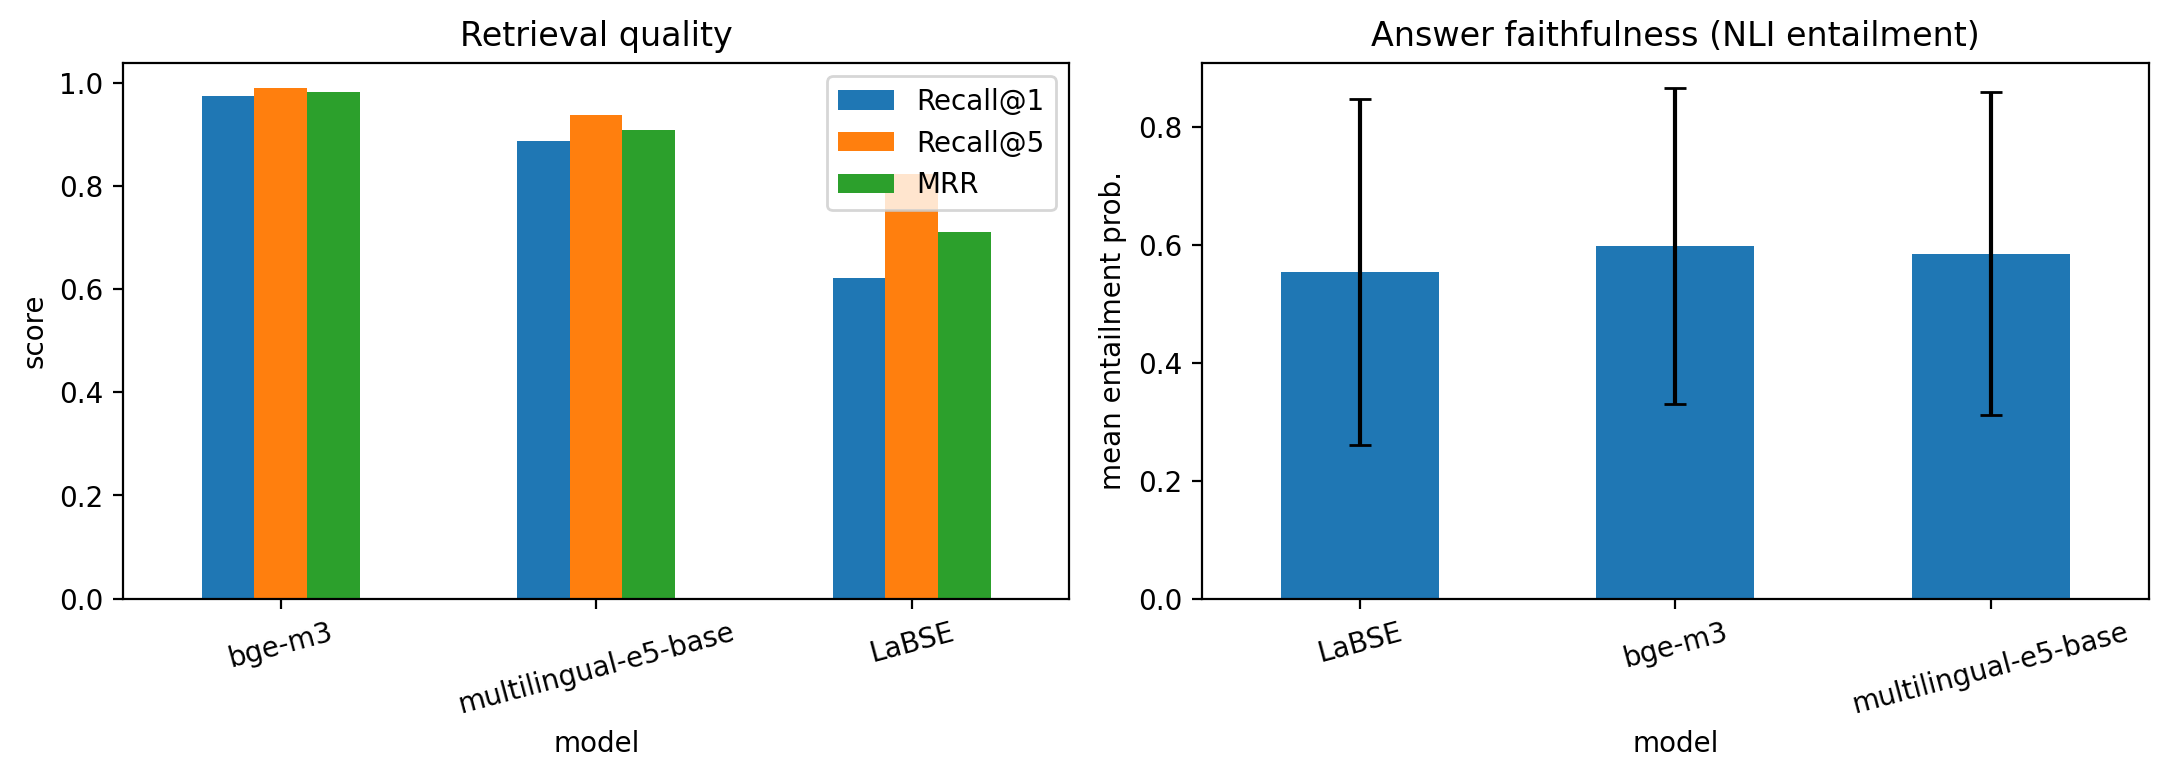

In [ ]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

retrieval_df.plot(x="model", y=["Recall@1", "Recall@5", "MRR"],
                  kind="bar", ax=axes[0], rot=15, title="Retrieval quality")
axes[0].set_ylabel("score")

summary["mean"].plot(kind="bar", ax=axes[1], rot=15, yerr=summary["std"],
                     capsize=4, title="Answer faithfulness (NLI entailment)")
axes[1].set_ylabel("mean entailment prob.")

plt.tight_layout()
fig.savefig(OUT_DIR / "comparison.png", dpi=200, bbox_inches="tight")
print(f"Saved: {OUT_DIR}/comparison.png")

from IPython.display import Image
Image(str(OUT_DIR / "comparison.png"))


Saved: results/faithfulness_heatmap.png


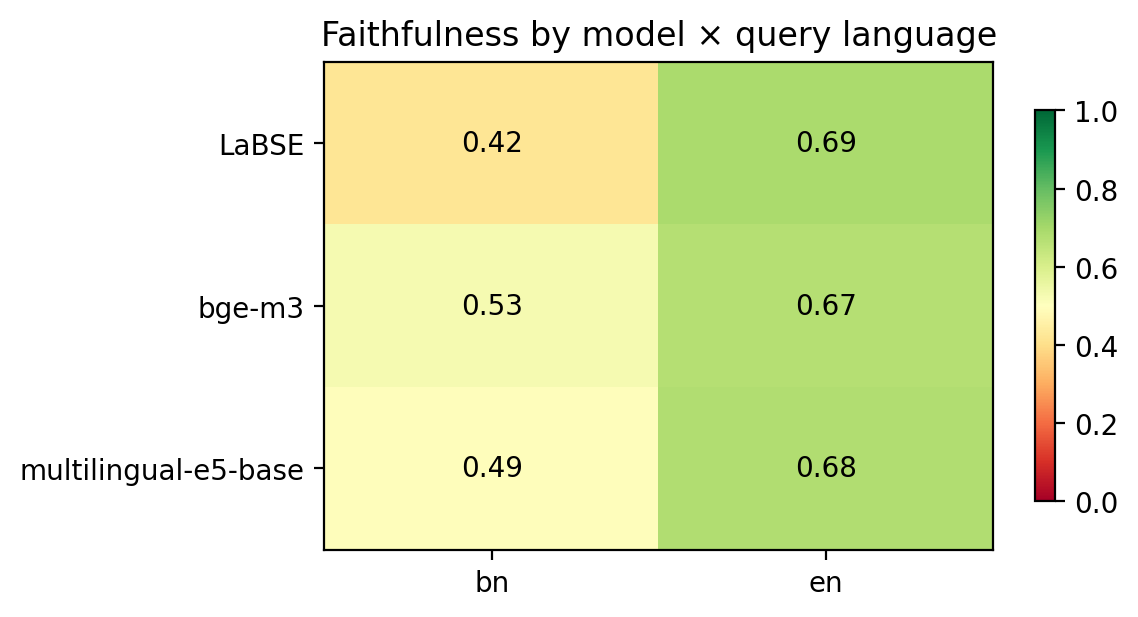

In [ ]:
# Per-language heatmap: where does each retriever fail?
pivot = faith_df.pivot_table(index="model", columns="lang",
                             values="faithfulness", aggfunc="mean")

fig, ax = plt.subplots(figsize=(6, 3.2))
im = ax.imshow(pivot.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.2f}", ha="center", va="center")
ax.set_title("Faithfulness by model × query language")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
fig.savefig(OUT_DIR / "faithfulness_heatmap.png", dpi=200, bbox_inches="tight")
print(f"Saved: {OUT_DIR}/faithfulness_heatmap.png")
Image(str(OUT_DIR / "faithfulness_heatmap.png"))


## 9. Additional baselines and significance tests: Oracle / Random / BM25 / Translate-then-Retrieve

Everything below reuses the variables already in memory from Sections 1-7 above
(`CORPUS`, `EN_QUERIES`, `bn_texts`, `QUERIES`, `per_model_results`, `faith_df`,
`generate_answer`, `faithfulness_scores`, `nli`, `DEVICE`, `OUT_DIR`, `N_CONTEXTS_FOR_GEN`,
`EMBEDDING_MODELS`, `MAX_SEQ_LEN`, `embed`), so keep running the cells top to bottom.

This section adds the experiments that help interpret the main results:

1. **Oracle RAG baseline**: feed the *guaranteed gold* passage directly to the generator, bypassing retrieval, for both EN and BN queries. Isolates whether the BN faithfulness drop is caused by retrieval or by the generator's own cross-lingual behaviour.
2. **Random retrieval baseline**: feed 3 random (non-gold) passages. Gives a lower bound on faithfulness under (almost) guaranteed-wrong evidence.
3. **BM25 sparse baseline**: classic lexical retrieval, both EN and BN queries directly against the English corpus.
4. **Translate-then-retrieve baseline**: back-translate the Bangla query to English with NLLB, then retrieve with the best dense retriever's English-English similarity.
5. **Paired bootstrap significance tests**: 95% CIs and p-values for the pairwise Recall@1 and faithfulness differences between the three retrievers.
6. **Passage truncation report**: what fraction of the 200 corpus passages exceed the 512-token cap used for embedding.

All results are written to `OUT_DIR` as CSVs, in the same style as Sections 1-7.

In [ ]:
import json, math, random
import numpy as np
import pandas as pd
import torch

random.seed(42)
np.random.seed(42)

assert 'CORPUS' in globals(), "Run Sections 1-7 above first (this cell reuses their variables)."
print(f"Corpus size: {len(CORPUS)} | Queries: {len(QUERIES)} | Models already retrieved: {list(per_model_results.keys())}")


Corpus size: 200 | Queries: 400 | Models already retrieved: ['bge-m3', 'multilingual-e5-base', 'LaBSE']


## 9.1 Oracle RAG baseline

Gold passage only (no retrieval). Run once for EN queries, once for BN queries.

In [ ]:
def run_oracle(queries_subset, tag):
    """queries_subset: list of (query_text, gold_id, lang). Feeds ONLY the gold passage to the generator."""
    rows = []
    for j, (q, gold_id, lang) in enumerate(queries_subset):
        contexts = [CORPUS[gold_id]]           # oracle: guaranteed-correct evidence, nothing else
        ans = generate_answer(q, contexts)
        rows.append({"query": q, "gold_id": gold_id, "lang": lang, "answer": ans, "contexts": contexts})
        if (j + 1) % 50 == 0:
            print(f"  [{tag}] generated {j + 1}/{len(queries_subset)}")
    return rows

en_subset = [(q, gid, "en") for q, gid in EN_QUERIES]
bn_subset = [(bn, gid, "bn") for bn, (_, gid) in zip(bn_texts, EN_QUERIES)]

print("[oracle] English queries + gold passage ...")
oracle_en_rows = run_oracle(en_subset, "oracle-en")
print("[oracle] Bangla queries + (English) gold passage ...")
oracle_bn_rows = run_oracle(bn_subset, "oracle-bn")

oracle_rows = oracle_en_rows + oracle_bn_rows
oracle_answers   = [r["answer"] for r in oracle_rows]
oracle_contexts  = [r["contexts"] for r in oracle_rows]
oracle_scores    = faithfulness_scores(oracle_answers, oracle_contexts)

for r, s in zip(oracle_rows, oracle_scores):
    r["faithfulness"] = round(s, 4)

oracle_df = pd.DataFrame(oracle_rows)
oracle_df.to_csv(OUT_DIR / "oracle_faithfulness_per_query.csv", index=False)

oracle_summary = oracle_df.groupby("lang")["faithfulness"].agg(["mean", "std", "count"]).round(4)
oracle_summary.to_csv(OUT_DIR / "oracle_faithfulness_summary.csv")
print("=== Oracle RAG faithfulness (gold passage only, no retrieval) ===")
display(oracle_summary)

# side-by-side with the best real retriever (bge-m3) for the paper's discussion
best_model = "bge-m3"
best_by_lang = faith_df[faith_df.model == best_model].groupby("lang")["faithfulness"].mean().round(4)
print(f"\nFor comparison — {best_model} (real retrieval, top-3 passages), from the main notebook:")
print(best_by_lang)
print("\nInterpretation guide:")
print("  oracle_en vs oracle_bn  -> gap purely from the GENERATOR reading EN / writing BN (no retrieval involved)")
print("  oracle_bn vs bge-m3 bn  -> how much of the real BN gap retrieval failure adds on top of that generator gap")


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[oracle] English queries + gold passage ...


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [oracle-en] generated 50/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [oracle-en] generated 100/200


... (10 outputs left out)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [oracle-bn] generated 200/200
=== Oracle RAG faithfulness (gold passage only, no retrieval) ===


,mean,std,count
lang,,,
bn,0.4443,0.2713,200
en,0.6092,0.2759,200



For comparison — bge-m3 (real retrieval, top-3 passages), from the main notebook:
lang
bn    0.5263
en    0.6695
Name: faithfulness, dtype: float64

Interpretation guide:
  oracle_en vs oracle_bn  -> gap purely from the GENERATOR reading EN / writing BN (no retrieval involved)
  oracle_bn vs bge-m3 bn  -> how much of the real BN gap retrieval failure adds on top of that generator gap


## 9.2 Random retrieval baseline

Three random non-gold passages per query — an approximate lower bound on faithfulness.

In [ ]:
def run_random_baseline(queries_subset, tag, k=3):
    all_ids = list(CORPUS.keys())
    rows = []
    for j, (q, gold_id, lang) in enumerate(queries_subset):
        pool = [pid for pid in all_ids if pid != gold_id]
        chosen = random.sample(pool, k)
        contexts = [CORPUS[pid] for pid in chosen]
        ans = generate_answer(q, contexts)
        rows.append({"query": q, "gold_id": gold_id, "lang": lang, "answer": ans, "contexts": contexts})
        if (j + 1) % 50 == 0:
            print(f"  [{tag}] generated {j + 1}/{len(queries_subset)}")
    return rows

print("[random] English queries + 3 random passages ...")
random_en_rows = run_random_baseline(en_subset, "random-en")
print("[random] Bangla queries + 3 random passages ...")
random_bn_rows = run_random_baseline(bn_subset, "random-bn")

random_rows = random_en_rows + random_bn_rows
random_answers  = [r["answer"] for r in random_rows]
random_contexts = [r["contexts"] for r in random_rows]
random_scores   = faithfulness_scores(random_answers, random_contexts)
for r, s in zip(random_rows, random_scores):
    r["faithfulness"] = round(s, 4)

random_df = pd.DataFrame(random_rows)
random_df.to_csv(OUT_DIR / "random_faithfulness_per_query.csv", index=False)
random_summary = random_df.groupby("lang")["faithfulness"].agg(["mean", "std", "count"]).round(4)
random_summary.to_csv(OUT_DIR / "random_faithfulness_summary.csv")
print("=== Random-passage faithfulness (lower bound) ===")
display(random_summary)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[random] English queries + 3 random passages ...


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [random-en] generated 50/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [random-en] generated 100/200


... (9 outputs left out)

  [random-bn] generated 150/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

  [random-bn] generated 200/200
=== Random-passage faithfulness (lower bound) ===


,mean,std,count
lang,,,
bn,0.2616,0.2926,200
en,0.4527,0.2211,200


## 9.3 Bounds table (oracle / real retrievers / random)

Assembles the faithfulness bound comparison: random (lower bound) < real
retrievers < oracle (upper bound, modulo the generator's own cross-lingual limitation).

In [ ]:
bounds_rows = []
for lang in ["en", "bn"]:
    bounds_rows.append({"condition": "random (lower bound)", "lang": lang,
                         "faithfulness": random_summary.loc[lang, "mean"]})
    for m in per_model_results.keys():
        v = faith_df[(faith_df.model == m) & (faith_df.lang == lang)]["faithfulness"].mean()
        bounds_rows.append({"condition": m, "lang": lang, "faithfulness": round(v, 4)})
    bounds_rows.append({"condition": "oracle (gold passage, upper bound)", "lang": lang,
                         "faithfulness": oracle_summary.loc[lang, "mean"]})

bounds_df = pd.DataFrame(bounds_rows)
bounds_pivot = bounds_df.pivot(index="condition", columns="lang", values="faithfulness")
bounds_pivot.to_csv(OUT_DIR / "faithfulness_bounds_table.csv")
print("=== Faithfulness bounds: random < retrievers < oracle ===")
display(bounds_pivot)


=== Faithfulness bounds: random < retrievers < oracle ===


lang,bn,en
condition,,
LaBSE,0.4206,0.6878
bge-m3,0.5263,0.6695
multilingual-e5-base,0.4938,0.6763
"oracle (gold passage, upper bound)",0.4443,0.6092
random (lower bound),0.2616,0.4527


## 9.4 BM25 sparse retrieval baseline

`pip install rank_bm25` if not already available.

In [ ]:
!pip install -q rank_bm25
from rank_bm25 import BM25Okapi
import re as _re

def simple_tokenize(text):
    return _re.findall(r"\w+", text.lower())

corpus_ids = list(CORPUS.keys())
tokenized_corpus = [simple_tokenize(CORPUS[i]) for i in corpus_ids]
bm25 = BM25Okapi(tokenized_corpus)

def bm25_retrieve(query_text, k=5):
    scores = bm25.get_scores(simple_tokenize(query_text))
    order = np.argsort(-scores)[:k]
    return [corpus_ids[i] for i in order]

def bm25_recall_mrr(queries_subset, k_values=(1, 5)):
    ranks = []
    for q, gold_id, lang in queries_subset:
        ranked = bm25_retrieve(q, k=10)
        try:
            ranks.append(ranked.index(gold_id) + 1)
        except ValueError:
            ranks.append(None)
    out = {}
    for k in k_values:
        out[f"Recall@{k}"] = float(np.mean([1.0 if (r or math.inf) <= k else 0.0 for r in ranks]))
    out["MRR"] = float(np.mean([1.0 / r if r else 0.0 for r in ranks]))
    return out

bm25_en = bm25_recall_mrr(en_subset)
bm25_bn = bm25_recall_mrr(bn_subset)
bm25_rows = [
    {"model": "BM25", "lang": "en", **bm25_en},
    {"model": "BM25", "lang": "bn", **bm25_bn},
]
bm25_df = pd.DataFrame(bm25_rows)
bm25_df.to_csv(OUT_DIR / "bm25_retrieval_by_lang.csv", index=False)
print("=== BM25 sparse retrieval (lexical, no cross-lingual training) ===")
display(bm25_df)
print("\nExpected: BM25 EN should be reasonable (lexical overlap works for EN-EN), BM25 BN should be")
print("near-zero, since Bangla query tokens share almost no surface form with the English corpus —")
print("this is the practical baseline dense multilingual retrievers need to beat for BN to be worthwhile.")


=== BM25 sparse retrieval (lexical, no cross-lingual training) ===


,model,lang,Recall@1,Recall@5,MRR
0,BM25,en,0.960,0.98,0.968750
1,BM25,bn,0.095,0.11,0.105062



Expected: BM25 EN should be reasonable (lexical overlap works for EN-EN), BM25 BN should be
near-zero, since Bangla query tokens share almost no surface form with the English corpus —
this is the practical baseline dense multilingual retrievers need to beat for BN to be worthwhile.


## 9.5 Translate-then-retrieve baseline

Back-translate the Bangla query to English with NLLB (ben\_Beng $\to$ eng\_Latn), then retrieve with the
best dense retriever (bge-m3) using English-English similarity. Compares an explicit MT+monolingual-retrieval
pipeline against bge-m3's direct cross-lingual retrieval on the same Bangla queries.

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

back_mt_name = "facebook/nllb-200-distilled-600M"
back_tok = AutoTokenizer.from_pretrained(back_mt_name, src_lang="ben_Beng")
back_model = AutoModelForSeq2SeqLM.from_pretrained(
    back_mt_name, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32
).to(DEVICE)

def back_translate_bn_to_en(texts, batch_size=32):
    out_texts = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = back_tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
        out = back_model.generate(
            **inputs, forced_bos_token_id=back_tok.convert_tokens_to_ids("eng_Latn"), max_new_tokens=256,
        )
        out_texts.extend(back_tok.batch_decode(out, skip_special_tokens=True))
        print(f"  back-translated {min(i + batch_size, len(texts))}/{len(texts)}")
    return out_texts

bn_backtranslated_en = back_translate_bn_to_en(bn_texts)
del back_model
if DEVICE == "cuda":
    torch.cuda.empty_cache()

print("\nExample round-trip:")
print("Original EN:", EN_QUERIES[0][0])
print("BN (NLLB):  ", bn_texts[0])
print("Back to EN: ", bn_backtranslated_en[0])


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  back-translated 32/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  back-translated 64/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  back-translated 96/200


... (2 outputs left out)

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  back-translated 160/200


[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  back-translated 192/200
  back-translated 200/200

Example round-trip:
Original EN: Is eligibility for a chemotherapy protocol a good prognostic factor for invasive bladder cancer after radical cystectomy?
BN (NLLB):   রসায়ন থেরাপি প্রোটোকলের জন্য যোগ্যতা কি পরামিতিগত সাইস্টেক্টমি পরে আক্রমণাত্মক ব্লাস্টার ক্যান্সারের জন্য একটি ভাল ভবিষ্যদ্বাণীমূলক কারণ?
Back to EN:  Is qualification for chemotherapy protocols a good predictor for aggressive blast cancer after particle cystektomy?


In [ ]:
from sentence_transformers import SentenceTransformer

best_hf_id = EMBEDDING_MODELS["bge-m3"]
bge_model = SentenceTransformer(best_hf_id, device=DEVICE)
bge_model.max_seq_length = MAX_SEQ_LEN

passage_ids = list(CORPUS.keys())
passage_emb = embed(bge_model, [CORPUS[i] for i in passage_ids])          # English corpus, English encoder
backtrans_emb = embed(bge_model, bn_backtranslated_en)                     # back-translated BN->EN queries

sims = backtrans_emb @ passage_emb.T
ranks = []
for row, (_, gold_id) in zip(sims, EN_QUERIES):
    order = np.argsort(-row)
    ranked_ids = [passage_ids[i] for i in order]
    ranks.append(ranked_ids.index(gold_id) + 1)

translate_then_retrieve = {
    "Recall@1": float(np.mean([1.0 if r <= 1 else 0.0 for r in ranks])),
    "Recall@5": float(np.mean([1.0 if r <= 5 else 0.0 for r in ranks])),
    "MRR": float(np.mean([1.0 / r for r in ranks])),
}
del bge_model
if DEVICE == "cuda":
    torch.cuda.empty_cache()

direct_bn = {
    "Recall@1": float(np.mean([1.0 if (r.rank_of_gold() or math.inf) <= 1 else 0.0
                                 for r in per_model_results['bge-m3'] if r.lang == 'bn'])),
    "Recall@5": float(np.mean([1.0 if (r.rank_of_gold() or math.inf) <= 5 else 0.0
                                 for r in per_model_results['bge-m3'] if r.lang == 'bn'])),
    "MRR": float(np.mean([1.0 / r.rank_of_gold() if r.rank_of_gold() else 0.0
                            for r in per_model_results['bge-m3'] if r.lang == 'bn'])),
}

compare_df = pd.DataFrame([
    {"pipeline": "bge-m3 direct cross-lingual (BN query -> multilingual embedding)", **direct_bn},
    {"pipeline": "NLLB back-translate BN->EN, then bge-m3 EN-EN retrieval", **translate_then_retrieve},
])
compare_df.to_csv(OUT_DIR / "translate_then_retrieve_vs_direct.csv", index=False)
print("=== Translate-then-retrieve vs. direct cross-lingual dense retrieval (Bangla queries) ===")
display(compare_df)


=== Translate-then-retrieve vs. direct cross-lingual dense retrieval (Bangla queries) ===


,pipeline,Recall@1,Recall@5,MRR
0,bge-m3 direct cross-lingual (BN query -> multi...,0.955,0.985,0.968750
1,"NLLB back-translate BN->EN, then bge-m3 EN-EN ...",0.970,0.990,0.978135


## 9.6 Paired bootstrap significance tests

95% CIs and two-sided bootstrap p-values for pairwise Recall@1 and faithfulness differences between the
three retrievers, using the paired structure (same 400 queries scored by every model).

In [ ]:
def paired_bootstrap(a, b, n_boot=10000, seed=42):
    """a, b: arrays of per-query scores (same length, same query order) for two models.
    Returns (mean_diff, ci_low, ci_high, p_value) for a - b."""
    rng = np.random.default_rng(seed)
    a, b = np.asarray(a), np.asarray(b)
    n = len(a)
    diffs = a - b
    obs = diffs.mean()
    boot_means = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n)
        boot_means[i] = diffs[idx].mean()
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    # two-sided p-value: proportion of bootstrap means that cross 0 relative to observed direction
    p = 2 * min((boot_means >= 0).mean(), (boot_means <= 0).mean())
    p = min(p, 1.0)
    return obs, ci_low, ci_high, p

# ---- Recall@1 (binary per-query hit/miss), paired across the same 400 queries ----
model_names = list(per_model_results.keys())
recall_hits = {}
for m in model_names:
    hits = [1.0 if (r.rank_of_gold() or math.inf) <= 1 else 0.0 for r in per_model_results[m]]
    recall_hits[m] = np.array(hits)

sig_rows = []
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        m1, m2 = model_names[i], model_names[j]
        obs, lo, hi, p = paired_bootstrap(recall_hits[m1], recall_hits[m2])
        sig_rows.append({"metric": "Recall@1", "model_a": m1, "model_b": m2,
                          "diff": round(obs, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                          "p_value": round(p, 4)})

# ---- Faithfulness, paired across the same 400 queries (faith_df preserves query order per model) ----
faith_by_model = {m: faith_df[faith_df.model == m].reset_index(drop=True) for m in model_names}
for i in range(len(model_names)):
    for j in range(i + 1, len(model_names)):
        m1, m2 = model_names[i], model_names[j]
        a = faith_by_model[m1]["faithfulness"].values
        b = faith_by_model[m2]["faithfulness"].values
        obs, lo, hi, p = paired_bootstrap(a, b)
        sig_rows.append({"metric": "Faithfulness", "model_a": m1, "model_b": m2,
                          "diff": round(obs, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4),
                          "p_value": round(p, 4)})

sig_df = pd.DataFrame(sig_rows)
sig_df.to_csv(OUT_DIR / "significance_tests.csv", index=False)
print("=== Paired bootstrap 95% CIs and p-values (10,000 resamples) ===")
display(sig_df)


=== Paired bootstrap 95% CIs and p-values (10,000 resamples) ===


,metric,model_a,model_b,diff,ci_low,ci_high,p_value
0,Recall@1,bge-m3,multilingual-e5-base,0.0875,0.0600,0.1175,0.0000
1,Recall@1,bge-m3,LaBSE,0.3525,0.3050,0.4000,0.0000
2,Recall@1,multilingual-e5-base,LaBSE,0.2650,0.2150,0.3125,0.0000
3,Faithfulness,bge-m3,multilingual-e5-base,0.0128,-0.0135,0.0397,0.3378
4,Faithfulness,bge-m3,LaBSE,0.0437,0.0154,0.0729,0.0022
5,Faithfulness,multilingual-e5-base,LaBSE,0.0308,0.0023,0.0599,0.0352


## 9.7 Passage truncation report (512-token cap)

Reports what fraction of the 200 corpus passages exceed the 512-token cap used for embedding, using
each embedding model's own tokenizer, and whether truncation could plausibly remove the answer-bearing
part of any gold passage.

In [ ]:
from transformers import AutoTokenizer

trunc_rows = []
for name, hf_id in EMBEDDING_MODELS.items():
    tok = AutoTokenizer.from_pretrained(hf_id)
    lengths = [len(tok.encode(CORPUS[pid], add_special_tokens=True)) for pid in CORPUS]
    lengths = np.array(lengths)
    n_over = int((lengths > MAX_SEQ_LEN).sum())
    trunc_rows.append({
        "model": name,
        "n_passages": len(lengths),
        "n_exceeding_512": n_over,
        "pct_exceeding_512": round(100 * n_over / len(lengths), 2),
        "mean_tokens": round(float(lengths.mean()), 1),
        "max_tokens": int(lengths.max()),
    })
    del tok

trunc_df = pd.DataFrame(trunc_rows)
trunc_df.to_csv(OUT_DIR / "passage_truncation_report.csv", index=False)
print("=== Passage length vs. 512-token embedding cap ===")
display(trunc_df)
print("\nIf pct_exceeding_512 is 0 (typical for PubMedQA abstracts, which run well under 512 tokens),")
print("truncation cannot explain any of the reported retrieval or faithfulness gaps -- report this")
print("explicitly in the paper.")


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (518 > 512). Running this sequence through the model will result in indexing errors
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (562 > 512). Running this sequence through the model will result in indexing errors


=== Passage length vs. 512-token embedding cap ===


,model,n_passages,n_exceeding_512,pct_exceeding_512,mean_tokens,max_tokens
0,bge-m3,200,8,4.0,327.6,593
1,multilingual-e5-base,200,8,4.0,327.6,593
2,LaBSE,200,4,2.0,297.8,562



If pct_exceeding_512 is 0 (typical for PubMedQA abstracts, which run well under 512 tokens),
truncation cannot explain any of the reported retrieval or faithfulness gaps -- report this
explicitly in the paper.


## 9.8 Summary printout

Run this last. It prints the numbers from this section in one place.

In [ ]:
print("ORACLE (gold passage, no retrieval):")
print(oracle_summary, "\n")

print("RANDOM (lower bound):")
print(random_summary, "\n")

print("BOUNDS TABLE (random < retrievers < oracle):")
print(bounds_pivot, "\n")

print("BM25:")
print(bm25_df, "\n")

print("TRANSLATE-THEN-RETRIEVE vs DIRECT (Bangla):")
print(compare_df, "\n")

print("SIGNIFICANCE TESTS:")
print(sig_df, "\n")

print("TRUNCATION REPORT:")
print(trunc_df)
